# 07. 의미 임베딩 비교와 관련 기억 검색 (2단계 로컬 실험)

일기 하나 → 행성 하나. 2단계에서는 **행성 위치를 일기 의미로** 정한다. 이 노트북은 그 첫 부분인
"일기 → 의미 임베딩 → 관련 기억 검색"을 확인하고, 임베딩 모델 3종을 비교한다. 좌표 생성은 `08_positioning.ipynb`.

> **합성 pilot 평가입니다.** 평가 일기 76개는 개발자가 직접 쓴 가상 일기이고, 관련성(0·1·2)도 작성자가 정한 규칙입니다.
> 실제 사용자 일기 성능이나 사람 평가 결과가 아닙니다. 수치는 모델 간 **상대 비교와 동작 확인용**으로만 봅니다.

**설계 기준**
- 위치 = 의미, 감정 = 색·밝기(1단계). 같은 주제·다른 감정은 관련될 수 있고, 감정만 같은 다른 주제는 연결하지 않는다.
- 관련성 판단은 **원본 임베딩(코사인 유사도)** 으로 한다. 3D 거리는 시각화용이다.
- 코사인 유사도는 확률이 아니다. 연결 여부는 **dev에서 정한 임계값 τ** 로만 판단하고, test 결과를 본 뒤 τ를 바꾸지 않는다.
- 관련 기록이 없으면 억지로 연결하지 않는다(τ 미만이면 연결 없음).

**모델(학습·미세조정 없음, 공식 카드 사용법 그대로)** — 설정: `ai/configs/embedding_models.json`

| 키 | 모델 | 라이선스 | pooling | 정규화 | prefix | 최대 길이 | 차원 |
|---|---|---|---|---|---|---|---|
| kure_v1 | nlpai-lab/KURE-v1 | MIT | CLS | L2 | 없음 | 8192 | 1024 |
| bge_m3 | BAAI/bge-m3 (dense) | MIT | CLS | L2 | 없음 | 8192 | 1024 |
| e5_small | intfloat/multilingual-e5-small | MIT | mean | L2 | `query: ` (양쪽) | 512 | 384 |

코드: `ai/src/embedding/encoders.py`(모델 wrapper), `ai/src/embedding/retrieval.py`(관련성·검색 평가)

## 1. 환경

In [1]:
import os
import sys
import json
import warnings
from pathlib import Path


def find_ai_root(start: Path) -> Path:
    """현재 위치에서 위로 올라가며 ai/ 폴더를 찾는다(저장소 루트·ai/·ai/notebooks/ 어디서든 실행 가능)."""
    for p in [start, *start.parents]:
        if p.name == "ai" and (p / "src" / "data" / "paths.py").is_file():
            return p
        if (p / "ai" / "src" / "data" / "paths.py").is_file():
            return p / "ai"
    raise FileNotFoundError("ai/ 폴더를 찾지 못했습니다. 저장소 안에서 실행하세요.")


AI_ROOT = find_ai_root(Path.cwd().resolve())
if str(AI_ROOT) not in sys.path:
    sys.path.insert(0, str(AI_ROOT))

# 커널 점검: 저장소 .venv(2단계 패키지 포함)가 아니면 여기서 멈추고 안내한다.
from src.env_check import assert_environment
ENV = assert_environment(AI_ROOT / "requirements-step2.txt", AI_ROOT.parent)

from src.data.paths import get_paths, configure_hf_cache, load_json

P = get_paths(AI_ROOT)
configure_hf_cache(P)                       # transformers import 전에 호출 (모델 캐시 = ai/.cache, Git 제외)
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
os.environ["HF_HUB_DISABLE_SYMLINKS_WARNING"] = "1"
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
warnings.filterwarnings("ignore", message=".*symlinks.*")
warnings.filterwarnings("ignore", message="IProgress not found")
warnings.filterwarnings("ignore", message=".*n_jobs value 1 overridden.*")


def rel(p) -> str:
    """저장소 기준 상대 경로(개인 PC 경로를 출력하지 않기 위해)."""
    return Path(p).resolve().relative_to(P.repo_root).as_posix()


EXP = load_json(P.configs / "step2_experiment.json")
MODELS_CFG = load_json(P.configs / "embedding_models.json")
OUT = P.ai_root / EXP["outputs_dir"]
EMB_DIR, REVIEW_DIR, FIG_DIR, RES_DIR = OUT / "embeddings", OUT / "review", OUT / "figures", OUT / "results"
for d in (EMB_DIR, REVIEW_DIR, FIG_DIR, RES_DIR):
    d.mkdir(parents=True, exist_ok=True)
print("결과 폴더:", rel(OUT), "(Git 제외)")

Python 3.13.5 | 저장소 .venv 커널 사용: 예
  numpy            필요 2.5.3      설치 2.5.3            OK
  pandas           필요 3.0.6      설치 3.0.6            OK
  pyarrow          필요 25.0.1     설치 25.0.1           OK
  matplotlib       필요 3.11.2     설치 3.11.2           OK
  huggingface_hub  필요 1.33.0     설치 1.33.0           OK
  transformers     필요 5.19.0     설치 5.19.0           OK
  ipykernel        필요 7.4.0      설치 7.4.0            OK
  torch            필요 2.14.1+cu130 설치 2.14.1+cu130     OK
  scikit-learn     필요 1.9.1      설치 1.9.1            OK
  umap-learn       필요 0.5.12     설치 0.5.12           OK
  plotly           필요 7.1.0      설치 7.1.0            OK
  psutil           필요 7.2.2      설치 7.2.2            OK
결과 폴더: ai/outputs/step2 (Git 제외)


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import display

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 70)
ANALYSIS_CFG = load_json(P.configs / "analysis.json")
installed_fonts = {f.name for f in font_manager.fontManager.ttflist}
KOREAN_FONT = next((f for f in ANALYSIS_CFG["figure"]["korean_font_candidates"] if f in installed_fonts), None)
if KOREAN_FONT:
    plt.rcParams["font.family"] = KOREAN_FONT
else:
    print("경고: 한글 글꼴을 찾지 못했습니다.")
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["axes.axisbelow"] = True
plt.rcParams["figure.dpi"] = ANALYSIS_CFG["figure"]["dpi"]
for side in ("top", "right"):
    plt.rcParams[f"axes.spines.{side}"] = False
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#8a5cd6"]


def show_fmt(df: pd.DataFrame, formats: dict, index: bool = True):
    """숫자 표시 형식만 바꿔 보여준다(원본 DataFrame은 그대로)."""
    d = df.copy()
    for c, f in formats.items():
        if c in d:
            d[c] = d[c].map(lambda v, f=f: f.format(v) if pd.notna(v) else "")
    display(d if index else d.reset_index(drop=True))


def save_fig(fig, path: Path):
    path.parent.mkdir(parents=True, exist_ok=True)
    with warnings.catch_warnings(record=True) as w:
        warnings.simplefilter("always")
        fig.savefig(path, bbox_inches="tight", facecolor=fig.get_facecolor())
    missing = [x for x in w if "missing from font" in str(x.message)]
    print(f"그림 저장: {rel(path)}" + (f" | 글꼴 누락 경고 {len(missing)}건" if missing else " | 글꼴 누락 없음"))

import torch
from src.embedding.encoders import load_specs, TextEncoder, time_encoding, process_rss_mb
from src.embedding import retrieval as RT

SPECS = load_specs(MODELS_CFG)
KS = tuple(EXP["retrieval"]["ks"])
K_LINK = EXP["retrieval"]["k_link"]
DEVICE = MODELS_CFG["device"]
if DEVICE.startswith("cuda"):
    assert torch.cuda.is_available(), "GPU(CUDA)를 찾지 못했습니다. 다른 프로그램이 GPU를 쓰는지 확인하세요."
    free, total = torch.cuda.mem_get_info()
    print(f"실행 장치: {DEVICE} ({torch.cuda.get_device_name(0)}) | GPU 여유 메모리 {free / 2**30:.1f} / {total / 2**30:.1f} GB")
else:
    print("실행 장치:", DEVICE, "| CPU 스레드", torch.get_num_threads())
print("torch", torch.__version__, "|", MODELS_CFG["device_note"])

실행 장치: cuda (NVIDIA GeForce RTX 4060 Ti) | GPU 여유 메모리 6.9 / 8.0 GB
torch 2.14.1+cu130 | GPU(RTX 4060 Ti 8GB, float32)로 추론한다. 모델은 한 번에 하나만 GPU에 올리고 다음 모델 전에 내린다. 2026-10-26 첫 실행은 GPU가 다른 학습에 점유돼 CPU였고, 2026-10-27에 GPU로 다시 실행했다.


## 2. 가상 일기 평가셋

- 파일: `ai/configs/pilot_diaries.json` (개인정보 없음, 개발자 작성)
- 주제 8개(공부·일·가족·친구·연애·운동건강·여행·반려동물) + 독립 기록. 각 기록: `diary_id`, `text`, 주제 태그, 사건(thread), 정서(pos/neg/neu), 사례 유형.
- **dev/test는 사건 단위로 분리**했다. 같은 사건의 변형 문장이 양쪽에 걸치지 않는다(아래에서 확인).
- 관련성 정의(같은 split 안에서만, 자기 자신 제외)

| 값 | 의미 | 판정 |
|---|---|---|
| 2 | 직접 관련 | 같은 사건, 또는 같은 대상이 이어지는 쌍(`relevance_overrides`, 6쌍) |
| 1 | 넓은 주제만 유사 | 주제 태그가 겹치지만 다른 사건 |
| 0 | 근거 부족 | 겹치는 주제 없음 (같은 단어만 겹치는 혼동 쌍 포함) |

같은 주제 태그라고 전부 2로 두지 않았다. 메타데이터(주제·사건·정서)는 **평가에만** 쓰고 모델 입력에는 `text`만 넣는다.

In [3]:
DF, RAW = RT.load_pilot(P.configs / EXP["dataset"])
R_ALL, REASON = RT.build_relevance(DF, RAW)
print(f"일기 {len(DF)}개 | dev {int((DF.split == 'dev').sum())} · test {int((DF.split == 'test').sum())} | 버전 {RAW['version']}")

# 누수 점검: 같은 사건이 dev·test 양쪽에 있으면 안 된다. 같은 문장 중복도 없어야 한다.
thr = DF.dropna(subset=["thread"]).groupby("thread")["split"].nunique()
assert (thr == 1).all(), thr[thr > 1]
assert DF["text"].duplicated().sum() == 0 and DF["diary_id"].is_unique
print("누수 점검: 사건이 두 split에 걸친 경우 0건, 중복 문장 0건")

topic_rows = DF.explode("topics").groupby(["topics", "split"]).size().unstack(fill_value=0)
display(topic_rows)
case_counts = DF.explode("case_types").dropna(subset=["case_types"]).groupby(["case_types", "split"]).size().unstack(fill_value=0)
display(case_counts)
print("정서 분포:", DF.groupby(["split", "valence"]).size().to_dict())
print("글자 수: 최소", DF.n_chars.min(), "· 중앙", int(DF.n_chars.median()), "· 최대", DF.n_chars.max())

일기 76개 | dev 38 · test 38 | 버전 pilot-0.1
누수 점검: 사건이 두 split에 걸친 경우 0건, 중복 문장 0건


split,dev,test
topics,,
exercise_health,4,5
family,5,5
friend,5,4
isolated_blackout,1,0
isolated_blood_donation,0,1
isolated_dream,1,0
isolated_driving_test,1,0
isolated_lost_parcel,0,1
isolated_moving,0,1


split,dev,test
case_types,,
diff_expression_same_activity,3,4
diff_topic_same_emotion,2,3
isolated,3,3
long,1,2
mixed_topic,3,3
same_topic_diff_emotion,22,20
same_word_diff_event,6,4
short,3,3


정서 분포: {('dev', 'neg'): 17, ('dev', 'neu'): 3, ('dev', 'pos'): 18, ('test', 'neg'): 17, ('test', 'neu'): 4, ('test', 'pos'): 17}
글자 수: 최소 17 · 중앙 61 · 최대 220


In [4]:
# 관련성 분포(쌍 단위, i<j)
iu, ju = np.triu_indices(len(DF), 1)
pair_rel = pd.Series(R_ALL[iu, ju])
pair_split = DF["split"].to_numpy()[iu]
dist = pd.crosstab(pair_split[pair_rel >= 0], pair_rel[pair_rel >= 0].to_numpy(), rownames=["split"], colnames=["관련성"])
display(dist)

# 검토용 표 저장(로컬, Git 제외): 일기 목록 + 관련성 1·2 쌍과 혼동 쌍
review_diaries = DF.assign(topics=DF.topics.map("+".join), case_types=DF.case_types.map(",".join))[
    ["diary_id", "split", "topics", "thread", "valence", "case_types", "length_group", "n_chars", "text"]]
review_pairs = RT.relevance_review_table(DF, RAW, R_ALL, REASON)
NOTE = "# 합성 pilot 평가용 가상 일기(개발자 작성). 실제 사용자 일기·사람 평가 아님.\n"
for name, t in [("pilot_diaries_review.csv", review_diaries), ("pilot_relevance_pairs_review.csv", review_pairs)]:
    with open(REVIEW_DIR / name, "w", encoding="utf-8-sig", newline="") as f:
        f.write(NOTE)
        t.to_csv(f, index=False)
    print("검토용 표 저장:", rel(REVIEW_DIR / name), f"({len(t)}행)")
display(review_pairs.query("relevance == 2").head(8))
display(review_pairs[review_pairs.confuser_word != ""])

관련성,0,1,2
split,,,
dev,631,52,20
test,631,54,18


검토용 표 저장: ai/outputs/step2/review/pilot_diaries_review.csv (76행)
검토용 표 저장: ai/outputs/step2/review/pilot_relevance_pairs_review.csv (150행)


,split,a,b,relevance,reason,confuser_word,paraphrase,a_text,b_text
0,dev,D001,D002,2,same_thread:study_math_midterm,,,다음 주 수학 중간고사인데 미적분 단원이 하나도 이해가 안 된다. 문제집을 펴 놓고 한 시간 동안 같은 문제,수학 중간고사 점수가 나왔는데 생각보다 훨씬 잘 봤다. 미적분 문제를 거의 다 맞혔다. 그동안 밤마다 문제
8,dev,D003,D004,2,same_thread:study_group_presentation,,,조별 과제 발표가 사흘 남았는데 조원 두 명이 단톡방에 답이 없다. 자료 조사도 내가 거의 다 했는데 PPT,드디어 조별 과제 발표 끝! 교수님이 질문도 좋게 받아주셨다. 막판에 조원들도 열심히 해줘서 다행이었다.
12,dev,D005,D006,2,same_thread:work_cafe_parttime,,카페 알바 / 매장 마감·커피,"주말 카페 알바, 손님이 끝도 없이 들어와서 쉬는 시간도 없이 음료만 만들었다. 손목이 시큰거리고 다리가 퉁",오늘 매장 마감하고 나오는데 사장님이 요즘 라떼 아트가 많이 늘었다고 칭찬해 주셨다. 커피 내리는 일이 점점
16,dev,D005,D035,2,override:같은 카페 알바,,,"주말 카페 알바, 손님이 끝도 없이 들어와서 쉬는 시간도 없이 음료만 만들었다. 손목이 시큰거리고 다리가 퉁","기말 기간인데 카페 알바 스케줄을 뺄 수가 없어서 오전엔 도서관, 오후엔 알바, 밤엔 다시 공부를 했다. 알"
19,dev,D006,D035,2,override:같은 카페 알바,,,오늘 매장 마감하고 나오는데 사장님이 요즘 라떼 아트가 많이 늘었다고 칭찬해 주셨다. 커피 내리는 일이 점점,"기말 기간인데 카페 알바 스케줄을 뺄 수가 없어서 오전엔 도서관, 오후엔 알바, 밤엔 다시 공부를 했다. 알"
20,dev,D007,D008,2,same_thread:work_intern_first_week,,,인턴 첫 출근. 팀 회의에서 갑자기 자기소개 겸 짧은 발표를 시켜서 머리가 하얘졌다. 사내 메신저랑 결재 시,인턴 생활 일주일째. 사수님이 엑셀 정리하는 방법을 차근차근 알려주셔서 처음으로 맡은 업무를 혼자 끝냈다.
23,dev,D009,D010,2,same_thread:family_mom_birthday,,,엄마 생신이라 동생이랑 몰래 케이크를 사 왔다. 촛불 끄면서 엄마가 소녀처럼 웃으셨다.,엄마 생신 선물로 뭘 사야 할지 일주일째 고민 중이다. 작년에 드린 목도리는 거의 안 하시는 것 같아서 이번
30,dev,D011,D012,2,same_thread:family_grandma_hospital,,,할머니가 넘어지셔서 병원에 입원하셨다는 연락을 받았다. 수업이 끝나자마자 병원으로 갔는데 링거를 맞고 계신,할머니 퇴원하시는 날. 다리는 아직 불편하시지만 집에 오시자마자 내 밥부터 챙기셨다. 오랜만에 마음이 놓였다


,split,a,b,relevance,reason,confuser_word,paraphrase,a_text,b_text
4,dev,D001,D036,0,no_shared_topic,시험 (수학 중간고사 / 운전면허 필기),,다음 주 수학 중간고사인데 미적분 단원이 하나도 이해가 안 된다. 문제집을 펴 놓고 한 시간 동안 같은 문제,운전면허 필기시험을 봤는데 한 번에 붙었다. 이제 기능시험만 남았다.
9,dev,D003,D007,0,no_shared_topic,발표 (조별 과제 / 인턴 회의 자기소개),,조별 과제 발표가 사흘 남았는데 조원 두 명이 단톡방에 답이 없다. 자료 조사도 내가 거의 다 했는데 PPT,인턴 첫 출근. 팀 회의에서 갑자기 자기소개 겸 짧은 발표를 시켜서 머리가 하얘졌다. 사내 메신저랑 결재 시
15,dev,D005,D022,0,no_shared_topic,시큰 (알바 손목 / 달리기 무릎),,"주말 카페 알바, 손님이 끝도 없이 들어와서 쉬는 시간도 없이 음료만 만들었다. 손목이 시큰거리고 다리가 퉁",하프 마라톤 대회를 앞두고 저녁마다 동네를 달리고 있는데 오늘은 무릎이 시큰해서 반도 못 뛰고 걸어 들어왔다
31,dev,D011,D031,0,no_shared_topic,병원·입원 (할머니 / 동물병원),,할머니가 넘어지셔서 병원에 입원하셨다는 연락을 받았다. 수업이 끝나자마자 병원으로 갔는데 링거를 맞고 계신,고양이가 이틀째 밥을 안 먹어서 동물병원에 데려갔다. 피검사를 해야 한다는데 결과 나올 때까지 아무것도 손에
79,test,D039,D045,0,no_shared_topic,마감 (기말 리포트 / 회사 서비스 오픈),,기말 리포트 마감이 내일 아침 9시인데 아직 절반밖에 못 썼다. 참고문헌 정리까지 하려면 오늘 밤도 못 잘,회사 신규 서비스 오픈이 다음 주라 이번 주 내내 야근이다. 기획서가 세 번이나 바뀌어서 이미 만든 화면을
127,test,D061,D063,0,no_shared_topic,배 (배탈 / 유람선),,어제 먹은 회가 잘못됐는지 새벽부터 배가 너무 아팠다. 장염이라고 해서 오늘은 링거 맞고 하루 종일 굶었다.,부산 여행 중에 태종대에서 유람선을 탔다. 배 위에서 보는 절벽이 생각보다 훨씬 웅장했다.


## 3. 작은 실행: 가상 일기 10개 (KURE-v1)

전체 비교 전에 dev 일기 10개로 임베딩 차원·정규화·유사도·자기 자신 제외 검색이 맞게 동작하는지 먼저 확인한다.

In [5]:
smoke_cfg = EXP["smoke_test"]
smoke = DF[DF.split == "dev"].head(smoke_cfg["n_diaries"]).reset_index(drop=True)
enc = TextEncoder(SPECS[smoke_cfg["model"]], device=MODELS_CFG["device"]).load()
E_s = enc.encode(smoke.text.tolist())
print("모델:", enc.spec.model_id, "| embedding_version:", enc.embedding_version)
print("모양:", E_s.shape, E_s.dtype, "| L2 노름 범위:", f"{np.linalg.norm(E_s, axis=1).min():.6f} ~ {np.linalg.norm(E_s, axis=1).max():.6f}")
S_s = RT.cosine_matrix(E_s)
print("대각(자기 자신) 유사도:", np.round(np.diag(S_s), 4).tolist())
m = (DF.split == "dev").to_numpy()
R_s = R_ALL[np.ix_(m, m)][:len(smoke), :len(smoke)]
display(pd.DataFrame(S_s, index=smoke.diary_id, columns=smoke.diary_id).round(3))
rows = []
for i in range(len(smoke)):
    order = RT.ranked_candidates(S_s, R_s, i)[:3]     # 자기 자신은 후보에서 제외됨
    assert i not in order
    rows.append({"질의": smoke.diary_id[i], "사건": smoke.thread[i],
                 "top3": ", ".join(f"{smoke.diary_id[j]}({S_s[i, j]:.3f}, 관련성 {R_s[i, j]})" for j in order)})
display(pd.DataFrame(rows))
top1_ok = np.mean([R_s[i, RT.ranked_candidates(S_s, R_s, i)[0]] == 2 for i in range(len(smoke))])
print(f"10개 중 top-1이 같은 사건(관련성 2)인 비율: {top1_ok:.0%}")
enc.close()
del enc

모델: nlpai-lab/KURE-v1 | embedding_version: kure_v1:nlpai-lab/KURE-v1@8b418a584146:cls:l2
모양: (10, 1024) float32 | L2 노름 범위: 1.000000 ~ 1.000000
대각(자기 자신) 유사도: [1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]


diary_id,D001,D002,D003,D004,D005,D006,D007,D008,D009,D010
diary_id,,,,,,,,,,
D001,1.000,0.666,0.557,0.454,0.430,0.308,0.417,0.445,0.367,0.488
D002,0.666,1.000,0.393,0.584,0.391,0.405,0.365,0.443,0.442,0.401
D003,0.557,0.393,1.000,0.627,0.455,0.380,0.579,0.543,0.305,0.471
D004,0.454,0.584,0.627,1.000,0.390,0.493,0.474,0.528,0.329,0.353
D005,0.430,0.391,0.455,0.390,1.000,0.564,0.473,0.483,0.394,0.434
D006,0.308,0.405,0.380,0.493,0.564,1.000,0.391,0.472,0.426,0.381
D007,0.417,0.365,0.579,0.474,0.473,0.391,1.000,0.672,0.323,0.476
D008,0.445,0.443,0.543,0.528,0.483,0.472,0.672,1.000,0.370,0.433
D009,0.367,0.442,0.305,0.329,0.394,0.426,0.323,0.370,1.000,0.510


,질의,사건,top3
0,D001,study_math_midterm,"D002(0.666, 관련성 2), D003(0.557, 관련성 1), D010(0.488, 관련성 0)"
1,D002,study_math_midterm,"D001(0.666, 관련성 2), D004(0.584, 관련성 1), D008(0.443, 관련성 0)"
2,D003,study_group_presentation,"D004(0.627, 관련성 2), D007(0.579, 관련성 0), D001(0.557, 관련성 1)"
3,D004,study_group_presentation,"D003(0.627, 관련성 2), D002(0.584, 관련성 1), D008(0.528, 관련성 0)"
4,D005,work_cafe_parttime,"D006(0.564, 관련성 2), D008(0.483, 관련성 1), D007(0.473, 관련성 1)"
5,D006,work_cafe_parttime,"D005(0.564, 관련성 2), D004(0.493, 관련성 0), D008(0.472, 관련성 1)"
6,D007,work_intern_first_week,"D008(0.672, 관련성 2), D003(0.579, 관련성 0), D010(0.476, 관련성 0)"
7,D008,work_intern_first_week,"D007(0.672, 관련성 2), D003(0.543, 관련성 0), D004(0.528, 관련성 0)"
8,D009,family_mom_birthday,"D010(0.510, 관련성 2), D002(0.442, 관련성 0), D006(0.426, 관련성 0)"
9,D010,family_mom_birthday,"D009(0.510, 관련성 2), D001(0.488, 관련성 0), D007(0.476, 관련성 0)"


10개 중 top-1이 같은 사건(관련성 2)인 비율: 100%


## 4. 모델 3종 임베딩 생성과 자원 측정

1. **임베딩 생성**: 모델을 하나씩 올려 76개 일기를 인코딩하고 `ai/outputs/step2/embeddings/`에 저장한 뒤 메모리에서 내린다.
2. **자원 측정**: 같은 프로세스에서 모델을 바꿔 올리면 앞 모델이 쓰던 메모리를 재사용해 증가량이 작게 보인다.
   그래서 모델마다 **새 프로세스**(`ai/scripts/measure_embedding_resources.py`)에서 따로 잰다.
   - 로딩 시간(캐시에 받은 파일 → 메모리), 프로세스 메모리(RSS) 증가량·최대치(Windows peak working set)
   - 워밍업 3회 후 일기 1개 지연시간(20회 중앙값·90%), 76개 묶음(batch 16) 처리 시간

실행 조건: GPU(RTX 4060 Ti 8GB, float32). 지연시간은 GPU 계산이 끝나 결과를 CPU로 받기까지의 시간이다.
GPU 메모리는 `torch.cuda` 할당량(가중치 + 계산 중 최대치)이다. 같은 PC의 다른 프로그램이 GPU를 함께 쓰면 수치가 달라질 수 있다.
참고로 2026-10-26 CPU(24스레드) 실행에서는 일기 1개가 KURE-v1·bge-m3 약 57ms, e5-small 약 9ms였다.

In [6]:
import hashlib, subprocess

TEXTS = DF.text.tolist()
TEXT_SHA1 = hashlib.sha1("\n".join(TEXTS).encode("utf-8")).hexdigest()
EMB, TOKINFO = {}, {}
for key in EXP["model_order"]:
    spec = SPECS[key]
    enc = TextEncoder(spec, device=MODELS_CFG["device"], batch_size=MODELS_CFG["batch_size"]).load()
    E = enc.encode(TEXTS)
    lens = enc.token_lengths(TEXTS)
    assert E.shape == (len(DF), spec.dim) and np.allclose(np.linalg.norm(E, axis=1), 1, atol=1e-4)
    # 같은 입력을 다시 인코딩하면 같은 벡터가 나오는지(결정성) 확인
    assert np.allclose(enc.encode(TEXTS[:4]), E[:4], atol=1e-5)
    np.save(EMB_DIR / f"{key}.npy", E)
    (EMB_DIR / f"{key}.json").write_text(json.dumps({
        "embedding_version": enc.embedding_version, "model_id": spec.model_id, "revision": spec.revision,
        "ids": DF.diary_id.tolist(), "text_sha1": TEXT_SHA1, "dataset_version": RAW["version"],
        "device": MODELS_CFG["device"]}, ensure_ascii=False, indent=1), encoding="utf-8")
    EMB[key] = E
    TOKINFO[key] = {"tokens_max": max(lens), "tokens_median": float(np.median(lens)), "n_truncated": enc.n_truncated,
                    "embedding_version": enc.embedding_version}
    print(f"{key}: {E.shape} 저장 → {rel(EMB_DIR / (key + '.npy'))} | 토큰 최대 {max(lens)} | 잘림 {enc.n_truncated}건")
    enc.close()
    del enc

kure_v1: (76, 1024) 저장 → ai/outputs/step2/embeddings/kure_v1.npy | 토큰 최대 121 | 잘림 0건


bge_m3: (76, 1024) 저장 → ai/outputs/step2/embeddings/bge_m3.npy | 토큰 최대 121 | 잘림 0건


e5_small: (76, 384) 저장 → ai/outputs/step2/embeddings/e5_small.npy | 토큰 최대 124 | 잘림 0건


In [7]:
RESOURCE = []
for key in EXP["model_order"]:
    r = subprocess.run([sys.executable, str(P.ai_root / "scripts" / "measure_embedding_resources.py"), "--model", key],
                       capture_output=True, text=True, encoding="utf-8", cwd=str(P.repo_root))
    assert r.returncode == 0, r.stderr[-2000:]
    RESOURCE.append({**json.loads(r.stdout.strip().splitlines()[-1]), **TOKINFO[key]})
RES_DF = pd.DataFrame(RESOURCE).set_index("model")
RES_DF.to_csv(RES_DIR / "embedding_resources.csv", encoding="utf-8-sig")
cols = ["params_M", "dim_", "weights_fp32_MB", "load_s", "gpu_alloc_after_load_MB", "gpu_peak_alloc_MB", "peak_MB",
        "single_ms_median", "single_ms_p90", "batch_total_s", "batch_ms_per_text", "tokens_max", "tokens_median", "n_truncated"]
cols = [c for c in cols if c in RES_DF]
RES_DF["dim_"] = [SPECS[k].dim for k in RES_DF.index]
show_fmt(RES_DF[cols], {"params_M": "{:.0f}", "weights_fp32_MB": "{:.0f}", "load_s": "{:.1f}", "load_increase_MB": "{:.0f}",
                        "peak_MB": "{:.0f}", "gpu_alloc_after_load_MB": "{:.0f}", "gpu_peak_alloc_MB": "{:.0f}", "single_ms_median": "{:.1f}", "single_ms_p90": "{:.1f}", "batch_total_s": "{:.2f}",
                        "batch_ms_per_text": "{:.1f}", "tokens_median": "{:.0f}"})
print("gpu_alloc_after_load_MB = 모델을 GPU에 올린 뒤 할당량, gpu_peak_alloc_MB = 인코딩 중 최대 할당량, peak_MB = 프로세스 최대 CPU 메모리(로딩 과정 포함).")
print("weights_fp32_MB = 파라미터 수 × 4바이트(계산값).")

,params_M,weights_fp32_MB,load_s,gpu_alloc_after_load_MB,gpu_peak_alloc_MB,peak_MB,single_ms_median,single_ms_p90,batch_total_s,batch_ms_per_text,tokens_max,tokens_median,n_truncated
model,,,,,,,,,,,,,
kure_v1,568,2166,3.2,2166,2261,3335,10.3,10.6,0.37,4.9,121,37,0
bge_m3,568,2166,3.2,2166,2261,3334,10.0,10.8,0.37,4.9,121,37,0
e5_small,118,449,2.2,449,491,1813,5.8,6.0,0.08,1.1,124,40,0


gpu_alloc_after_load_MB = 모델을 GPU에 올린 뒤 할당량, gpu_peak_alloc_MB = 인코딩 중 최대 할당량, peak_MB = 프로세스 최대 CPU 메모리(로딩 과정 포함).
weights_fp32_MB = 파라미터 수 × 4바이트(계산값).


## 5. 관련 기억 검색 평가

- 질의 = 각 일기, 후보 = **같은 split의 다른 일기**(자기 자신 제외). 순위 = 코사인 유사도.
- 지표: Recall@k·Hit@k·MRR(관련성 2 기준), nDCG@k(이득 2→3, 1→1, 0→0), 상위 k 중 관련성 0 비율(무관 기록 연결 오류).
- 관련성 2가 없는 질의(복합 주제 일부)는 Recall·MRR에서 빼고, 관련 기록이 아예 없는 **고립 기록**은 따로 본다.
- 연결 규칙: 상위 3개 중 **sim ≥ τ** 인 것만 "관련 기억"으로 보여 준다. τ는 **dev 쌍**에서 F1(양성 = 관련성 2)이 최대인 값으로 정하고 test에 그대로 쓴다.

In [8]:
EVAL, TAU = {}, {}
for key in EXP["model_order"]:
    EVAL[key] = {}
    dfd, Ed, Rd = RT.split_view(DF, EMB[key], R_ALL, "dev")
    Sd = RT.cosine_matrix(Ed)
    TAU[key] = RT.choose_threshold(RT.pair_table(Sd, Rd, dfd), EXP["retrieval"]["threshold_positive_min_rel"])
    for split in ("dev", "test"):
        dfs, Es, Rs = RT.split_view(DF, EMB[key], R_ALL, split)
        EVAL[key][split] = RT.evaluate_split(RT.cosine_matrix(Es), Rs, dfs, TAU[key]["tau"], RAW, KS, K_LINK)
        EVAL[key][split]["S"], EVAL[key][split]["R"], EVAL[key][split]["df"] = RT.cosine_matrix(Es), Rs, dfs

tau_df = pd.DataFrame(TAU).T.rename(columns={"f1": "dev_pair_F1", "precision": "dev_pair_precision", "recall": "dev_pair_recall"})
print("dev에서 정한 연결 임계값 τ (모델마다 유사도 분포가 달라 따로 정함)")
show_fmt(tau_df, {c: "{:.3f}" for c in tau_df.columns})

rows = []
for key in EXP["model_order"]:
    for split in ("dev", "test"):
        s, l = EVAL[key][split]["summary"], EVAL[key][split]["links"]
        rows.append({"model": key, "split": split, **{k: s[k] for k in ["recall@1", "recall@3", "recall@5", "mrr_rel2", "ndcg@3", "ndcg@5", "unrelated@3"]},
                     "link_prec_rel2": l["link_precision_rel2"], "link_prec_rel1+": l["link_precision_rel1plus"],
                     "link_unrelated": l["link_unrelated_rate"], "rel2_coverage": l["rel2_pair_coverage"],
                     "isolated_false_link": l["isolated_false_link_rate"], "no_link_queries": l["queries_without_link"]})
MAIN = pd.DataFrame(rows).set_index(["model", "split"])
MAIN.to_csv(RES_DIR / "retrieval_main.csv", encoding="utf-8-sig")
show_fmt(MAIN, {c: "{:.3f}" for c in MAIN.columns if c != "no_link_queries"})
n_q = {s: EVAL["kure_v1"][s]["summary"] for s in ("dev", "test")}
print({s: {k: n_q[s][k] for k in ("n_queries", "n_with_direct", "n_isolated")} for s in n_q})

dev에서 정한 연결 임계값 τ (모델마다 유사도 분포가 달라 따로 정함)


,tau,dev_pair_F1,dev_pair_precision,dev_pair_recall
kure_v1,0.557,0.700,0.700,0.700
bge_m3,0.526,0.667,0.571,0.800
e5_small,0.897,0.647,0.786,0.550


recall@1 recall@3 recall@5 mrr_rel2 ndcg@3 ndcg@5 unrelated@3 link_prec_rel2 link_prec_rel1+ link_unrelated rel2_coverage isolated_false_link  no_link_queries
model    split                                                                                                                                                               
kure_v1  dev      0.765    0.926    0.971    0.907  0.757  0.762       0.491          0.700           0.850          0.150         0.700               0.000               11
         test     0.545    0.924    0.939    0.746  0.649  0.649       0.553          0.467           0.644          0.356         0.611               0.333               10
bge_m3   dev      0.706    0.941    0.941    0.869  0.732  0.708       0.526          0.604           0.755          0.245         0.800               0.000                9
         test     0.485    0.742    0.909    0.653  0.544  0.570       0.614          0.289           0.421          0.579         0.667               1.000                3
e5_small dev      0.721    0.868    0.941    0.847  0.692  0.704       0.544          0.786           0.786          0.214         0.550               0.000               17
         test     0.697    0.894    0.909    0.829  0.726  0.695       0.491          0.647           0.941          0.059         0.611               0.000               13

{'dev': {'n_queries': 38, 'n_with_direct': 34, 'n_isolated': 3}, 'test': {'n_queries': 38, 'n_with_direct': 33, 'n_isolated': 3}}


In [9]:
# 표본이 작아 질의 단위 부트스트랩으로 test 지표의 흔들림을 확인한다(모델 간 차이가 이 폭보다 작으면 우열을 단정하지 않음).
rng = np.random.default_rng(0)
boot_rows = []
for key in EXP["model_order"]:
    pq = EVAL[key]["test"]["per_query"]
    for metric in ("ndcg@5", "recall@3"):
        v = pq[metric].dropna().to_numpy()
        bs = [rng.choice(v, len(v)).mean() for _ in range(2000)]
        boot_rows.append({"model": key, "metric": metric, "mean": v.mean(), "ci95_low": np.percentile(bs, 2.5), "ci95_high": np.percentile(bs, 97.5), "n": len(v)})
BOOT = pd.DataFrame(boot_rows)
show_fmt(BOOT, {"mean": "{:.3f}", "ci95_low": "{:.3f}", "ci95_high": "{:.3f}"}, index=False)

,model,metric,mean,ci95_low,ci95_high,n
0,kure_v1,ndcg@5,0.649,0.570,0.722,35
1,kure_v1,recall@3,0.924,0.833,1.000,33
2,bge_m3,ndcg@5,0.570,0.486,0.642,35
3,bge_m3,recall@3,0.742,0.591,0.879,33
4,e5_small,ndcg@5,0.695,0.625,0.755,35
5,e5_small,recall@3,0.894,0.788,0.985,33


## 6. 사례 유형별 확인 (test, τ 고정)

- **같은 사건·다른 정서**: 기쁜 기록과 걱정한 기록이 같은 사건이면 서로 찾아야 한다(높을수록 좋음).
- **다른 주제·같은 정서**: 감정만 같은 다른 주제 기록이 상위·τ 위에 오면 안 된다(낮을수록 좋음).
- **주제>감정 AUC**: 한 질의에서 sim(같은 사건·다른 정서) > sim(다른 주제·같은 정서)일 확률.
- **혼동 쌍**(같은 단어·다른 사건)과 **표현이 다른 같은 활동** 쌍, **복합 주제**, **짧은·긴 기록**, **고립 기록**.

In [10]:
emo = pd.DataFrame({f"{k}/{s}": EVAL[k][s]["emotion"] for k in EXP["model_order"] for s in ("dev", "test")}).T
emo.to_csv(RES_DIR / "retrieval_emotion_vs_topic.csv", encoding="utf-8-sig")
show_fmt(emo, {c: "{:.3f}" for c in emo.columns if c != "n_queries_diff_emotion_partner"})

,n_queries_diff_emotion_partner,diff_emotion_partner_in_top3,topic_over_emotion_auc,same_emotion_unrelated_share_top3,same_emotion_unrelated_above_tau
kure_v1/dev,34.0,0.912,0.980,0.316,0.011
kure_v1/test,33.0,0.909,0.930,0.430,0.031
bge_m3/dev,34.0,0.941,0.970,0.307,0.026
bge_m3/test,33.0,0.727,0.886,0.482,0.102
e5_small/dev,34.0,0.882,0.961,0.237,0.004
e5_small/test,33.0,0.879,0.972,0.272,0.004


In [11]:
def pairs_side_by_side(kind):
    out = []
    for key in EXP["model_order"]:
        for split in ("dev", "test"):
            t = EVAL[key][split][kind].copy()
            if len(t):
                t.insert(0, "model", key); t.insert(1, "split", split)
                out.append(t)
    return pd.concat(out, ignore_index=True)

CONF = pairs_side_by_side("confusers")
PARA = pairs_side_by_side("paraphrases")
CONF.to_csv(RES_DIR / "retrieval_confuser_pairs.csv", index=False, encoding="utf-8-sig")
PARA.to_csv(RES_DIR / "retrieval_paraphrase_pairs.csv", index=False, encoding="utf-8-sig")
print("혼동 쌍(관련성 0): 순위가 낮고 above_tau=False여야 좋다")
display(CONF.pivot_table(index=["a", "b", "note"], columns="model", values=["sim", "rank_b_for_a", "above_tau"], aggfunc="first").round(3))
print("표현이 다른 같은 활동(관련성 2): 순위 1~2, above_tau=True여야 좋다")
display(PARA.pivot_table(index=["a", "b", "note"], columns="model", values=["sim", "rank_b_for_a", "above_tau"], aggfunc="first").round(3))
summary_pairs = pd.DataFrame({
    "confuser_above_tau": CONF.groupby("model")["above_tau"].mean(),
    "confuser_in_top3": CONF.assign(t=(CONF.rank_b_for_a <= 3) | (CONF.rank_a_for_b <= 3)).groupby("model")["t"].mean(),
    "paraphrase_above_tau": PARA.groupby("model")["above_tau"].mean(),
    "paraphrase_rank1": PARA.assign(t=(PARA.rank_b_for_a == 1) & (PARA.rank_a_for_b == 1)).groupby("model")["t"].mean(),
}).loc[EXP["model_order"]]
show_fmt(summary_pairs, {c: "{:.2f}" for c in summary_pairs.columns})

혼동 쌍(관련성 0): 순위가 낮고 above_tau=False여야 좋다


above_tau                  rank_b_for_a                     sim                 
model                                bge_m3 e5_small kure_v1       bge_m3 e5_small kure_v1 bge_m3 e5_small kure_v1
a    b    note                                                                                                    
D001 D036 시험 (수학 중간고사 / 운전면허 필기)      False    False   False           14       10      12  0.446    0.868   0.447
D003 D007 발표 (조별 과제 / 인턴 회의 자기소개)      True    False    True            2        4       2  0.569    0.885   0.579
D005 D022 시큰 (알바 손목 / 달리기 무릎)         False    False   False            4       12       4  0.502    0.870   0.533
D011 D031 병원·입원 (할머니 / 동물병원)          False    False   False           25       12      23  0.423    0.880   0.432
D039 D045 마감 (기말 리포트 / 회사 서비스 오픈)      True    False    True            2        2       2  0.583    0.882   0.583
D061 D063 배 (배탈 / 유람선)                False    False   False           36       36      34  0.376    0.833   0.393

표현이 다른 같은 활동(관련성 2): 순위 1~2, above_tau=True여야 좋다


above_tau                  rank_b_for_a                     sim                 
model                           bge_m3 e5_small kure_v1       bge_m3 e5_small kure_v1 bge_m3 e5_small kure_v1
a    b    note                                                                                               
D005 D006 카페 알바 / 매장 마감·커피        True     True    True            2        1       2  0.558    0.902   0.564
D021 D022 러닝 / 마라톤 대비 달리기        False    False   False            8        1       1  0.436    0.849   0.483
D041 D042 영어 회화 스터디 / 스피킹 모임     False    False   False            5        7       3  0.521    0.876   0.537
D049 D050 낚시 / 낚싯대·물가             True     True    True            1        1       1  0.642    0.903   0.678
D059 D060 헬스장 PT / 웨이트 트레이닝      False    False   False            3        1       2  0.508    0.891   0.537

,confuser_above_tau,confuser_in_top3,paraphrase_above_tau,paraphrase_rank1
model,,,,
kure_v1,0.33,0.50,0.40,0.20
bge_m3,0.33,0.33,0.40,0.20
e5_small,0.00,0.50,0.40,0.60


In [12]:
mixed = pd.concat([EVAL[k][s]["mixed"].assign(model=k, split=s) for k in EXP["model_order"] for s in ("dev", "test")], ignore_index=True)
print("복합 주제 기록: 상위 5개에 두 주제의 기록이 모두 있는가")
display(mixed.pivot_table(index=["split", "diary_id", "topics"], columns="model", values="all_topics_covered", aggfunc="first"))
by_len = pd.concat({k: EVAL[k]["test"]["by_length"] for k in EXP["model_order"]}, names=["model"])
print("길이별(test, 관련성 2가 있는 질의): recall@3·MRR")
show_fmt(by_len.unstack("length_group"), {c: "{:.3f}" for c in by_len.unstack("length_group").columns})
iso = []
for k in EXP["model_order"]:
    for s in ("dev", "test"):
        e = EVAL[k][s]; pq = e["per_query"]; S, R, d = e["S"], e["R"], e["df"]
        for i in np.flatnonzero(pq.isolated.to_numpy()):
            o = RT.ranked_candidates(S, R, i)[0]
            iso.append({"model": k, "split": s, "diary_id": d.diary_id[i], "top1": d.diary_id[o], "top1_sim": S[i, o],
                        "tau": TAU[k]["tau"], "linked(=오류)": bool(S[i, o] >= TAU[k]["tau"])})
ISO = pd.DataFrame(iso)
print("고립 기록(관련 기록 없음): top-1 유사도가 τ 미만이어야 '연결 없음'으로 처리된다")
display(ISO.pivot_table(index=["split", "diary_id"], columns="model", values=["top1_sim", "linked(=오류)"], aggfunc="first").round(3))

복합 주제 기록: 상위 5개에 두 주제의 기록이 모두 있는가

model                                bge_m3  e5_small  kure_v1
split diary_id topics                                         
dev   D033     friend+travel           True     False     True
      D034     family+pet              True      True     True
      D035     study+work              True      True     True
test  D071     romance+travel         False      True    False
      D072     work+exercise_health   False     False    False
      D073     family+pet              True      True     True

길이별(test, 관련성 2가 있는 질의): recall@3·MRR


recall@3               mrr_rel2              
length_group     long normal  short     long normal  short
model                                                     
kure_v1         1.000  0.950  0.500    0.500  0.769  0.529
bge_m3          0.000  0.783  0.500    0.200  0.677  0.519
e5_small        1.000  0.883  1.000    1.000  0.828  0.750

고립 기록(관련 기록 없음): top-1 유사도가 τ 미만이어야 '연결 없음'으로 처리된다


linked(=오류)                  top1_sim                 
model               bge_m3 e5_small kure_v1   bge_m3 e5_small kure_v1
split diary_id                                                       
dev   D036           False    False   False    0.497    0.874   0.482
      D037           False    False   False    0.526    0.889   0.537
      D038           False    False   False    0.510    0.873   0.535
test  D074            True    False   False    0.554    0.889   0.547
      D075            True    False   False    0.548    0.866   0.538
      D076            True    False    True    0.580    0.880   0.591

## 7. 관련성별 유사도 분포 (test)

그림 저장: ai/outputs/step2/figures/07_similarity_by_relevance.png | 글꼴 누락 없음


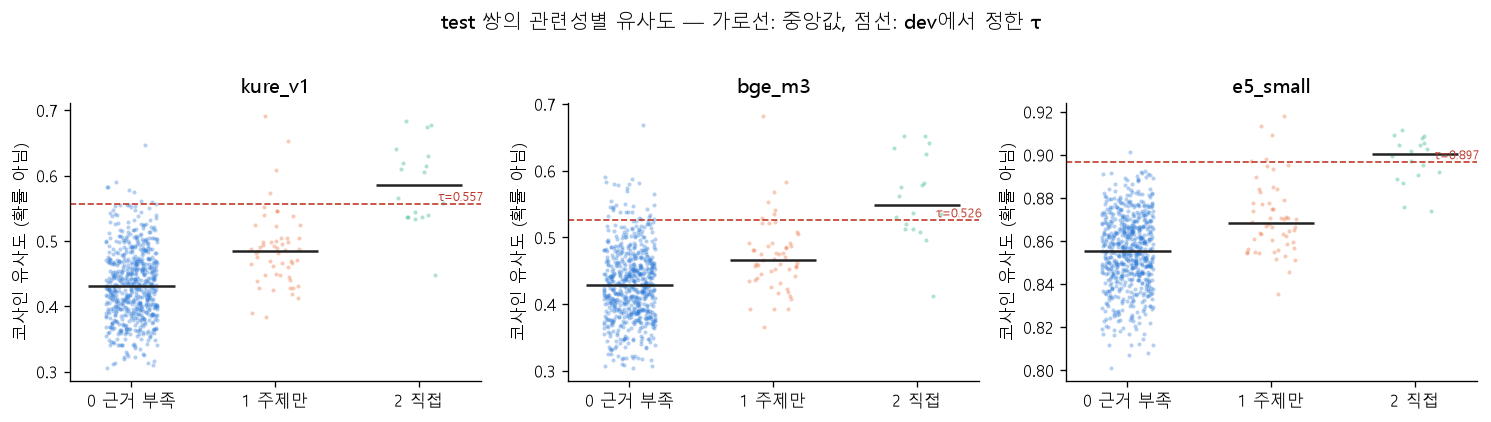

In [13]:
fig, axes = plt.subplots(1, len(EXP["model_order"]), figsize=(4.2 * len(EXP["model_order"]), 3.4), sharey=False)
for ax, key in zip(axes, EXP["model_order"]):
    e = EVAL[key]["test"]
    pt = RT.pair_table(e["S"], e["R"], e["df"])
    data = [pt.loc[pt.rel == r, "sim"].to_numpy() for r in (0, 1, 2)]
    for r, v in enumerate(data):
        x = np.full(len(v), r) + np.random.default_rng(r).uniform(-0.18, 0.18, len(v))
        ax.scatter(x, v, s=6, alpha=0.35, color=SERIES[r], linewidths=0)
        ax.hlines(np.median(v), r - 0.3, r + 0.3, color="#222", lw=1.5)
    ax.axhline(TAU[key]["tau"], color="#c0392b", ls="--", lw=1)
    ax.text(2.45, TAU[key]["tau"], f"τ={TAU[key]['tau']:.3f}", color="#c0392b", va="bottom", ha="right", fontsize=8)
    ax.set_xticks([0, 1, 2], ["0 근거 부족", "1 주제만", "2 직접"])
    ax.set_title(key)
    ax.set_ylabel("코사인 유사도 (확률 아님)")
fig.suptitle("test 쌍의 관련성별 유사도 — 가로선: 중앙값, 점선: dev에서 정한 τ", y=1.02)
fig.tight_layout()
save_fig(fig, FIG_DIR / "07_similarity_by_relevance.png")
plt.show()

## 8. 실패 사례 (test)

In [14]:
fails = []
for key in EXP["model_order"]:
    e = EVAL[key]["test"]; S, R, d = e["S"], e["R"], e["df"]
    for i in range(len(d)):
        top = RT.ranked_candidates(S, R, i)[:K_LINK]
        for j in top:
            if S[i, j] >= TAU[key]["tau"] and R[i, j] == 0:
                fails.append({"model": key, "query": d.diary_id[i], "linked": d.diary_id[j], "sim": S[i, j],
                              "query_text": d.text[i][:45], "linked_text": d.text[j][:45]})
FAILS = pd.DataFrame(fails)
FAILS.to_csv(RES_DIR / "retrieval_unrelated_links_test.csv", index=False, encoding="utf-8-sig")
print("τ 위로 연결됐지만 관련성 0인 쌍(무관 연결 오류) 수:", FAILS.groupby("model").size().reindex(EXP["model_order"], fill_value=0).to_dict())
display(FAILS.sort_values(["model", "sim"], ascending=[True, False]).groupby("model").head(6))
miss = []
for key in EXP["model_order"]:
    e = EVAL[key]["test"]; pq = e["per_query"]; d = e["df"]
    bad = pq[(pq.has_direct) & (pq["hit@3"] == 0)]
    for _, r in bad.iterrows():
        miss.append({"model": key, "query": r.diary_id, "top1": r.top1_id, "top1_rel": r.top1_rel,
                     "query_text": d.set_index("diary_id").text[r.diary_id][:50]})
print("직접 관련 기록(관련성 2)을 상위 3개 안에서 못 찾은 질의")
display(pd.DataFrame(miss))

τ 위로 연결됐지만 관련성 0인 쌍(무관 연결 오류) 수: {'kure_v1': 16, 'bge_m3': 44, 'e5_small': 2}


,model,query,linked,sim,query_text,linked_text
35,bge_m3,D052,D072,0.668726,룸메이트랑 날 잡고 진지하게 얘기했다. 서로 생활 규칙을 정하고 나니까 오히려 전,회사 동료들이랑 점심시간에 같이 헬스장에 가기로 했다. 업무 얘기만 하던 사이였는
49,bge_m3,D072,D052,0.668726,회사 동료들이랑 점심시간에 같이 헬스장에 가기로 했다. 업무 얘기만 하던 사이였는,룸메이트랑 날 잡고 진지하게 얘기했다. 서로 생활 규칙을 정하고 나니까 오히려 전
21,bge_m3,D042,D052,0.591210,스피킹 모임 나간 지 두 달째. 오늘은 원어민 멤버랑 10분 넘게 막힘없이 대화했,룸메이트랑 날 잡고 진지하게 얘기했다. 서로 생활 규칙을 정하고 나니까 오히려 전
36,bge_m3,D052,D042,0.591210,룸메이트랑 날 잡고 진지하게 얘기했다. 서로 생활 규칙을 정하고 나니까 오히려 전,스피킹 모임 나간 지 두 달째. 오늘은 원어민 멤버랑 10분 넘게 막힘없이 대화했
22,bge_m3,D042,D072,0.587318,스피킹 모임 나간 지 두 달째. 오늘은 원어민 멤버랑 10분 넘게 막힘없이 대화했,회사 동료들이랑 점심시간에 같이 헬스장에 가기로 했다. 업무 얘기만 하던 사이였는
50,bge_m3,D072,D042,0.587318,회사 동료들이랑 점심시간에 같이 헬스장에 가기로 했다. 업무 얘기만 하던 사이였는,스피킹 모임 나간 지 두 달째. 오늘은 원어민 멤버랑 10분 넘게 막힘없이 대화했
60,e5_small,D042,D072,0.901425,스피킹 모임 나간 지 두 달째. 오늘은 원어민 멤버랑 10분 넘게 막힘없이 대화했,회사 동료들이랑 점심시간에 같이 헬스장에 가기로 했다. 업무 얘기만 하던 사이였는
61,e5_small,D072,D042,0.901425,회사 동료들이랑 점심시간에 같이 헬스장에 가기로 했다. 업무 얘기만 하던 사이였는,스피킹 모임 나간 지 두 달째. 오늘은 원어민 멤버랑 10분 넘게 막힘없이 대화했
6,kure_v1,D052,D072,0.647247,룸메이트랑 날 잡고 진지하게 얘기했다. 서로 생활 규칙을 정하고 나니까 오히려 전,회사 동료들이랑 점심시간에 같이 헬스장에 가기로 했다. 업무 얘기만 하던 사이였는
12,kure_v1,D072,D052,0.647247,회사 동료들이랑 점심시간에 같이 헬스장에 가기로 했다. 업무 얘기만 하던 사이였는,룸메이트랑 날 잡고 진지하게 얘기했다. 서로 생활 규칙을 정하고 나니까 오히려 전


직접 관련 기록(관련성 2)을 상위 3개 안에서 못 찾은 질의


,model,query,top1,top1_rel,query_text
0,kure_v1,D043,D051,0,편의점 야간 알바 중에 술 취한 손님이 계산대 앞에서 한참 소리를 질렀다. 혼자라서 너무
1,kure_v1,D044,D048,0,"야간 알바 끝, 폐기 삼각김밥으로 아침 해결. 은근 맛있다."
2,bge_m3,D041,D054,0,영어 회화 스터디에 처음 나갔다. 다들 말을 술술 하는데 나만 단어가 안 떠올라서 자기소개
3,bge_m3,D043,D051,0,편의점 야간 알바 중에 술 취한 손님이 계산대 앞에서 한참 소리를 질렀다. 혼자라서 너무
4,bge_m3,D044,D048,0,"야간 알바 끝, 폐기 삼각김밥으로 아침 해결. 은근 맛있다."
5,bge_m3,D045,D039,0,회사 신규 서비스 오픈이 다음 주라 이번 주 내내 야근이다. 기획서가 세 번이나 바뀌어서
6,bge_m3,D056,D076,0,이별하고 한 달. 이제는 사진을 봐도 담담하다. 그 사람 물건을 상자에 담아 정리했다.
7,bge_m3,D060,D072,1,"웨이트 트레이닝 시작한 지 석 달, 오늘 데드리프트 개인 기록을 깼다. 몸이 달라지는 게"
8,bge_m3,D065,D071,1,가평으로 캠핑을 다녀왔다. 장작불 앞에서 고기를 굽고 밤하늘 별을 보다가 잠들었다.
9,bge_m3,D066,D071,1,캠핑장에 도착하자마자 비가 쏟아져서 텐트도 제대로 못 치고 차 안에서 밤을 보냈다.


## 9. 모델 선택 (미리 정한 규칙, dev만 사용)

규칙(`step2_experiment.json` → `selection_rule`): dev nDCG@5가 가장 높은 모델과 0.02 이내인 모델 중,
dev 무관 연결률이 가장 낮은 모델(0.02 이내 동률이면 일기 1개 지연시간이 짧은 모델). test는 선택 뒤 확인용으로만 본다.

In [15]:
rule = EXP["selection_rule"]
dev = MAIN.xs("dev", level="split")
cand = dev[dev["ndcg@5"] >= dev["ndcg@5"].max() - rule["tie_margin"]]
cand = cand[cand["link_unrelated"] <= cand["link_unrelated"].min() + rule["tie_margin"]]
SELECTED = RES_DF.loc[cand.index, "single_ms_median"].idxmin()
print("dev nDCG@5:", dev["ndcg@5"].round(3).to_dict())
print("후보(규칙 1·2 통과):", list(cand.index))
print("선택 모델:", SELECTED, "→", SPECS[SELECTED].model_id)
print("선택 모델 test 확인:", MAIN.loc[(SELECTED, "test"), ["recall@3", "ndcg@5", "link_unrelated", "isolated_false_link"]].round(3).to_dict())

results = {
    "note": "합성 pilot 평가(가상 일기 76개). 실제 사용자 성능·사람 평가 아님.",
    "dataset_version": RAW["version"], "text_sha1": TEXT_SHA1,
    "selected_model": SELECTED, "selection_rule": rule,
    "thresholds": {k: {**TAU[k], "embedding_version": RES_DF.loc[k, "embedding_version"]} for k in TAU},
    "main": {f"{k}/{s}": MAIN.loc[(k, s)].to_dict() for k, s in MAIN.index},
    "emotion_vs_topic": emo.to_dict(orient="index"),
    "resources": RES_DF.reset_index().to_dict(orient="records"),
    "bootstrap_test": BOOT.to_dict(orient="records"),
    "environment": {"python": ENV["python"], "torch": torch.__version__, "device": MODELS_CFG["device"], "cpu_threads": torch.get_num_threads()},
}
(RES_DIR / "retrieval_results.json").write_text(json.dumps(results, ensure_ascii=False, indent=1, default=float), encoding="utf-8")
print("저장:", rel(RES_DIR / "retrieval_results.json"))

dev nDCG@5: {'kure_v1': 0.762, 'bge_m3': 0.708, 'e5_small': 0.704}
후보(규칙 1·2 통과): ['kure_v1']
선택 모델: kure_v1 → nlpai-lab/KURE-v1
선택 모델 test 확인: {'recall@3': 0.924, 'ndcg@5': 0.649, 'link_unrelated': 0.356, 'isolated_false_link': 0.333}
저장: ai/outputs/step2/results/retrieval_results.json


## 10. 해석

> 합성 pilot(가상 일기 76개, 작성자가 정한 관련성) 결과다. 질의가 split당 38개뿐이라 수치 차이 0.05 안팎은 우연일 수 있다(5절 부트스트랩 구간 참고).

**작은 실행(3절)**: KURE-v1로 dev 10개를 넣었을 때 1024차원, L2 노름 1.000, 자기 자신은 후보에서 빠졌고, 10개 모두 top-1이 같은 사건 기록이었다. 파이프라인이 의도대로 동작한다.

**검색 순위 품질(5절)**
- dev nDCG@5: KURE-v1 0.762 > bge-m3 0.708 ≈ e5-small 0.704. 미리 정한 규칙에 따라 **KURE-v1을 선택**했다(08 좌표 비교에 사용).
- test: KURE-v1 Recall@3 0.924 · nDCG@5 0.649, e5-small 0.894 · 0.695, bge-m3 0.742 · 0.570.
  KURE와 e5의 test 구간이 겹쳐 둘 사이 우열은 단정할 수 없다. bge-m3는 dev·test 모두 KURE보다 낮았다(KURE는 bge-m3를 한국어 검색 데이터로 추가 학습한 모델).

**연결(τ) — 가장 큰 문제**
- dev에서 정한 τ를 test에 그대로 쓰면 KURE-v1은 연결의 35.6%가 관련성 0이었다(dev 15.0%). 고립 기록 3개 중 1개(D076 이사 짐 정리 ↔ D056 이별 후 물건 정리)도 연결됐다.
  bge-m3는 57.9%, 고립 3/3 연결. e5-small은 5.9%, 고립 0/3.
- KURE·bge는 관련성 0 쌍의 상단 꼬리가 τ 근처까지 올라온다(7절 그림). τ를 38개 dev로 정해 다른 일기 묶음으로 옮기면 흔들린다는 뜻이다.
  e5-small은 유사도가 0.80~0.92의 좁은 범위에 몰려 있어 τ(0.897)가 촘촘한 값이고, 분포가 조금만 달라져도 민감할 수 있다.
- 표현이 다른 같은 활동(러닝↔마라톤, 영어 회화↔스피킹, PT↔웨이트)은 세 모델 모두 순위 1~3위로는 찾지만 τ 위로 올라간 것은 5쌍 중 2쌍뿐이다(연결 누락).

**감정보다 주제를 따르는가(6절)**: 세 모델 모두 "같은 사건·다른 정서"를 "다른 주제·같은 정서"보다 높게 놓았다(주제>감정 AUC 0.89~0.98).
감정만 같은 다른 주제 기록이 τ 위에 오는 비율도 KURE 0.031, e5 0.004로 낮다. bge-m3는 test에서 0.102로 가장 높았다.

**같은 단어·다른 사건(혼동 쌍)**: "배"(배탈↔유람선), "병원"(할머니↔동물병원)은 세 모델 모두 순위가 낮아 잘 구분했다.
"발표"(조별 과제↔인턴 회의), "마감"(기말 리포트↔회사 오픈)은 KURE·bge에서 2위·τ 위로 연결됐다. 단어뿐 아니라 "압박·긴장" 상황도 비슷한 경계 사례다.

**실패 사례(8절)**: KURE는 편의점 야간 알바 2개(D043·D044)의 짝을 상위 3개 안에서 못 찾았다. 짧은 기록(D044 "야간 알바 끝, 폐기 삼각김밥…")이 특히 약하다(짧은 기록 Recall@3 KURE 0.50, e5 1.00, 표본 3개).
D052(룸메이트와 화해)↔D072(동료와 가까워짐)는 규칙상 관련성 0이지만, "관계가 좋아짐"이라는 공통 의미가 있어 사람에 따라 관련 있다고 볼 수 있는 **라벨 경계 사례**다.

**자원(4절, GPU RTX 4060 Ti·float32, 모델마다 새 프로세스에서 측정)**
- KURE-v1·bge-m3: 파라미터 568M, GPU 메모리 약 2.2GB(가중치)·인코딩 중 최대 약 2.3GB, 일기 1개 약 10ms, 76개 묶음 약 0.4초.
- e5-small: 118M, GPU 약 0.45GB·최대 약 0.5GB, 일기 1개 약 6ms, 76개 약 0.1초.
- GPU에서는 일기 1개 기준 KURE가 CPU(약 57ms)보다 약 5.7배 빨라졌고, 모델 간 속도 차이도 작아졌다(10ms vs 6ms).
- 검색 지표·τ는 CPU 실행(2026-10-26)과 소수 셋째 자리까지 같았다(연산 장치 차이는 결과에 영향 없음).
- 세 모델 모두 76개 일기 중 잘린 것은 없다(최대 124토큰).

**정리**
- 규칙에 따른 1순위는 **KURE-v1**이다. 다만 test에서 무관 연결이 많아, 지금 τ를 그대로 서비스 "관련 기억" 표시에 쓰기는 이르다.
- **e5-small**은 순위 품질이 KURE와 구간이 겹치고, 메모리가 약 1/4이며(GPU 0.5GB vs 2.3GB), test 무관 연결이 낮았다. test를 본 뒤 선택을 바꾸지는 않는다. 더 큰 dev셋에서 KURE와 다시 비교할 후보로 남긴다.
- 다음에 할 일: dev 일기를 늘려(주제·표현 다양화) τ를 다시 정하고, 사람 검토로 관련성 라벨의 경계 사례를 정리한다.